In [27]:
import numpy as np , pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler



In [28]:
df=pd.read_csv('Wholesale_Data.csv')
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [29]:
print(df.columns)
print(df.info)
print(df.describe)
print(df.shape)



Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='str')
<bound method DataFrame.info of      Channel  Region  Fresh   Milk  Grocery  Frozen  Detergents_Paper  \
0          2       3  12669   9656     7561     214              2674   
1          2       3   7057   9810     9568    1762              3293   
2          2       3   6353   8808     7684    2405              3516   
3          1       3  13265   1196     4221    6404               507   
4          2       3  22615   5410     7198    3915              1777   
..       ...     ...    ...    ...      ...     ...               ...   
435        1       3  29703  12051    16027   13135               182   
436        1       3  39228   1431      764    4510                93   
437        2       3  14531  15488    30243     437             14841   
438        1       3  10290   1981     2232    1038               168   
439        1       3   2787   1698    

In [30]:
print(df.dtypes)

Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object


In [31]:
print(df.isnull().sum())
print(df.duplicated().sum())

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64
0


In [32]:
cols = df.drop(["Channel","Region"], axis=1)
print(cols)


     Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0    12669   9656     7561     214              2674        1338
1     7057   9810     9568    1762              3293        1776
2     6353   8808     7684    2405              3516        7844
3    13265   1196     4221    6404               507        1788
4    22615   5410     7198    3915              1777        5185
..     ...    ...      ...     ...               ...         ...
435  29703  12051    16027   13135               182        2204
436  39228   1431      764    4510                93        2346
437  14531  15488    30243     437             14841        1867
438  10290   1981     2232    1038               168        2125
439   2787   1698     2510      65               477          52

[440 rows x 6 columns]


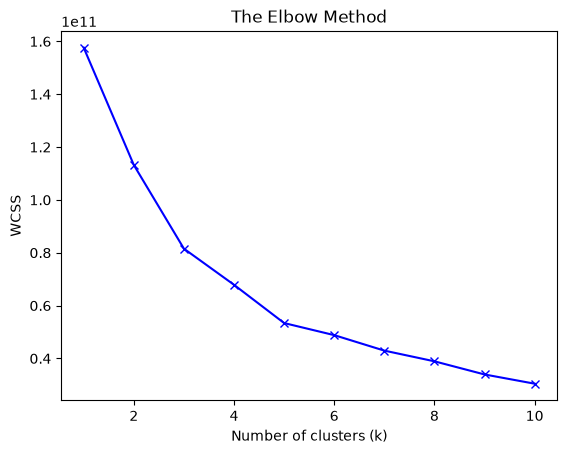

In [33]:
#Elbow rule
wcss = []
for i in range(1, 11):
 kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
 kmeans.fit(cols)
 wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, 'bx-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS')
plt.title('The Elbow Method')
plt.show()



In [34]:
#kmean
km = KMeans(n_clusters=6, n_init=10, random_state=42).fit(cols)
df["segment"] = km.labels_
print(km.labels_)
print(df['segment'])


[1 1 1 1 2 1 1 1 1 3 1 1 2 2 2 1 3 1 2 1 2 1 2 3 2 2 1 1 3 2 2 1 2 2 1 1 2
 3 3 0 2 2 3 3 1 3 3 4 1 3 1 1 2 3 2 1 3 3 1 1 1 4 1 3 1 3 1 2 1 1 2 2 1 2
 1 2 1 3 1 1 1 3 1 2 1 4 4 0 1 2 1 1 3 1 3 1 1 1 1 1 3 3 1 0 1 2 1 3 1 3 1
 3 2 1 2 1 1 1 2 1 2 1 1 1 2 0 2 2 1 2 1 1 1 1 1 1 1 1 1 1 2 2 2 1 2 3 1 1
 1 2 2 1 2 1 1 3 3 2 1 3 1 1 2 3 1 3 1 1 1 1 3 3 1 3 1 1 0 1 1 1 1 0 1 5 1
 1 1 1 1 3 2 1 1 3 1 2 2 1 1 1 3 3 2 1 1 3 1 1 1 3 2 3 1 1 1 3 3 2 3 1 1 1
 1 1 1 1 2 1 1 1 1 1 2 1 2 1 1 2 1 0 2 2 2 1 1 3 1 1 2 1 1 3 1 2 1 2 1 1 0
 0 1 1 2 1 3 3 3 2 3 1 1 1 1 2 1 1 2 1 1 2 1 1 0 2 0 2 1 2 2 2 1 1 1 3 2 1
 2 1 1 1 2 3 1 3 3 1 3 2 1 3 1 2 3 1 1 3 1 1 1 3 1 1 2 1 2 5 1 1 2 1 1 3 2
 4 2 2 1 1 1 1 1 1 1 3 1 1 3 2 1 3 1 3 1 3 1 1 2 3 1 1 2 1 1 1 1 1 1 1 2 1
 2 2 1 2 1 1 3 2 1 1 2 2 2 1 3 1 1 2 1 1 1 1 1 2 1 1 1 1 1 1 1 2 2 2 2 1 2
 3 1 1 1 1 1 1 1 1 3 1 3 1 3 2 2 2 2 1 3 2 1 1 1 1 2 1 2 2 2 3 1 1]
0      1
1      1
2      1
3      1
4      2
      ..
435    2
436    2
437    3
438    1
439    1
Name: se

In [35]:
#HC
clustering = AgglomerativeClustering(n_clusters=2).fit(cols)
print(clustering.labels_)

[0 0 0 0 1 0 0 0 0 0 0 0 1 1 1 0 0 0 1 0 1 0 1 0 1 1 0 1 0 1 1 0 1 1 0 0 1
 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1
 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0
 0 1 1 1 0 0 0 1 0 1 0 1 0 1 1 1 1 0 1 0 0 1 0 0 0 0 0 0 0 1 1 1 0 1 0 0 0
 0 1 1 0 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 0 1 0
 0 0 0 0 0 1 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0
 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 1 0 0 0 0 1 1 0 0 0 0 1 0 1 0 0 1
 1 0 0 1 0 0 0 0 1 0 1 0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 1 0 1 1 1 0 0 0 0 1 0
 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 1 1 0 0 1 0 0 0 1
 0 1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0
 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 1 1 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 0 0 1 0 0 0 0 1 0 1 1 1 0 0 0]


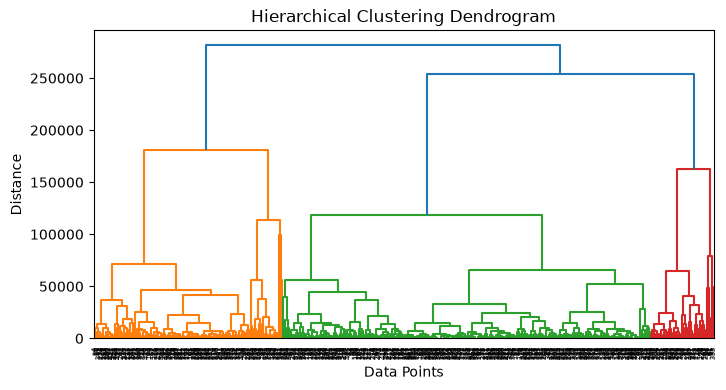

In [36]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
Z = linkage(cols, 'ward')

# Plot dendrogram
plt.figure(figsize=(8, 4))
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

In [37]:
#DBSCAN
db = DBSCAN(eps=0.9, min_samples=15).fit(cols)
labels = db.labels_
print("clusters:", len(set(labels)) - (1 if -1 in labels else 0))
print("noise points:", (labels == -1).sum())

clusters: 0
noise points: 440


variance kept: 0.8647858849391103


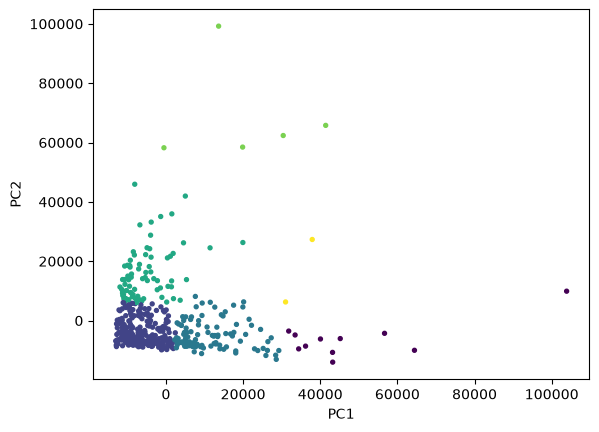

In [38]:
#PCA
pca = PCA(n_components=2)
X2 = pca.fit_transform(cols)
print("variance kept:", pca.explained_variance_ratio_.sum())
plt.scatter(X2[:, 0], X2[:, 1], c=km.labels_, cmap="viridis", s=8)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()